# Laptop pricing: turning messy spec sheets into a hedonic price model
**Question.** What is each specification worth? How much do buyers pay for RAM, SSD storage, a high-resolution screen, a discrete GPU or the brand itself, **holding everything else equal**? And how well can price be predicted from the spec sheet?

**Data.** 1,303 laptop listings (European retailer, 2017-2018) whose specifications arrive as free text: `"Intel Core i5 7200U 2.5GHz"`, `"128GB SSD +  1TB HDD"`, `"IPS Panel Retina Display 2560x1600"`, `"1.37kg"`, and prices written with a decimal comma.

**Method.** Parse every field into numbers and flags, then fit a **hedonic regression** (log price on characteristics, as used for consumer price indices) for interpretable premia, plus gradient boosting for prediction, each with cross-validation.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
import re, statsmodels.formula.api as smf
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.ensemble import HistGradientBoostingRegressor
raw = pd.read_csv("data/laptops.csv")
raw.columns = [c.strip() for c in raw.columns]
print(raw.shape); raw.head(3)

(1303, 13)


,Manufacturer,Model Name,Category,Screen Size,Screen,CPU,RAM,Storage,GPU,Operating System,Operating System Version,Weight,Price (Euros)
0,Apple,MacBook Pro,Ultrabook,"13.3""",IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,NaN,1.37kg,"1339,69"
1,Apple,Macbook Air,Ultrabook,"13.3""",1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,NaN,1.34kg,"898,94"
2,HP,250 G6,Notebook,"15.6""",Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,NaN,1.86kg,"575,00"


In [2]:
d = pd.DataFrame(index=raw.index)
d["brand"] = raw.Manufacturer; d["category"] = raw.Category
d["price_eur"] = raw["Price (Euros)"].str.replace(".", "", regex=False).str.replace(",", ".", regex=False).astype(float)
d["inches"] = raw["Screen Size"].str.rstrip('"').astype(float)
res = raw.Screen.str.extract(r"(\d+)x(\d+)").astype(float); d["megapixels"] = res[0] * res[1] / 1e6
d["ips"] = raw.Screen.str.contains("IPS").astype(int); d["touch"] = raw.Screen.str.contains("Touch").astype(int)
d["ram_gb"] = raw.RAM.str.rstrip("GB").astype(int)
def storage(s):
    out = {"ssd_gb": 0, "hdd_gb": 0, "flash_gb": 0}
    for part in s.split("+"):
        m = re.search(r"([\d.]+)(GB|TB)", part); size = float(m[1]) * (1000 if m[2] == "TB" else 1)
        key = "ssd_gb" if "SSD" in part else "hdd_gb" if "HDD" in part else "flash_gb" if "Flash" in part else "hdd_gb"
        out[key] += size
    return pd.Series(out)
d = d.join(raw.Storage.apply(storage))
d["cpu_ghz"] = raw.CPU.str.extract(r"([\d.]+)GHz")[0].astype(float)
d["cpu_family"] = np.select([raw.CPU.str.contains("i7"), raw.CPU.str.contains("i5"), raw.CPU.str.contains("i3"), raw.CPU.str.startswith("AMD")],
                            ["Core i7", "Core i5", "Core i3", "AMD"], "Celeron/Pentium/other")
d["gpu"] = np.select([raw.GPU.str.startswith("Nvidia"), raw.GPU.str.startswith("AMD")], ["Nvidia", "AMD"], "Integrated (Intel/ARM)")
d["os"] = raw["Operating System"].replace({"Mac OS": "macOS", "Linux": "Linux/none", "No OS": "Linux/none", "Chrome OS": "Chrome OS"})
# macOS only ships on Apple: fold it into the Windows baseline so the Apple brand dummy carries the effect (otherwise the two are collinear)
d["os_g"] = d.os.replace({"macOS": "Windows", "Windows 10 S": "Windows", "Windows 7": "Windows", "Windows 10": "Windows"})
d["weight_kg"] = pd.to_numeric(raw.Weight.str.replace("kgs", "").str.replace("kg", ""), errors="coerce")
print("unparsed values per column:", d.isna().sum()[d.isna().sum() > 0].to_dict())
d = d.dropna()
d.describe().T[["mean", "min", "max"]].round(2)

unparsed values per column: {}


,mean,min,max
price_eur,1123.69,174.00,6099.00
inches,15.02,10.10,18.40
megapixels,2.17,1.05,8.29
ips,0.28,0.00,1.00
touch,0.15,0.00,1.00
ram_gb,8.38,2.00,64.00
ssd_gb,183.05,0.00,1024.00
hdd_gb,422.62,0.00,2000.00
flash_gb,4.56,0.00,512.00
cpu_ghz,2.30,0.90,3.60


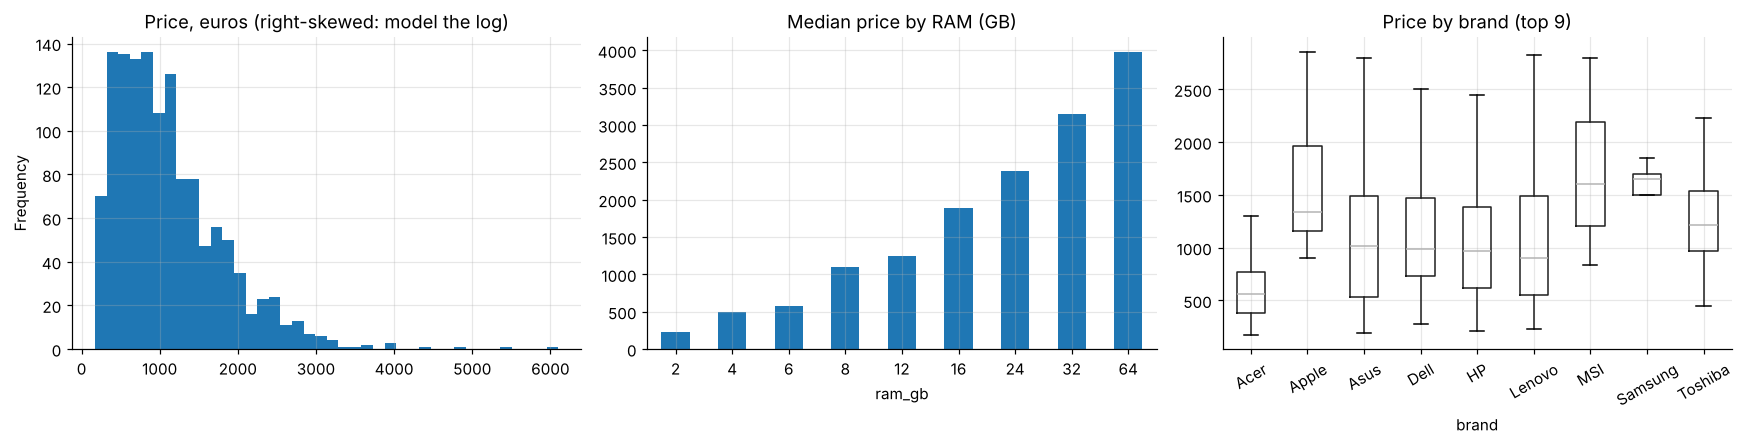

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
d.price_eur.plot.hist(bins=40, ax=axes[0], title="Price, euros (right-skewed: model the log)")
d.groupby("ram_gb").price_eur.median().plot.bar(ax=axes[1], rot=0, title="Median price by RAM (GB)")
order = d.groupby("brand").price_eur.median().sort_values().index
d[d.brand.isin(d.brand.value_counts().index[:9])].boxplot("price_eur", by="brand", ax=axes[2], rot=30, showfliers=False)
axes[2].set_title("Price by brand (top 9)"); plt.suptitle("")
plt.tight_layout(); plt.savefig(IMG / "eda.png", bbox_inches="tight"); plt.show()

## Hedonic regression: the price of each characteristic
$\ln(\text{price})$ on the parsed specs. The coefficient on a 0/1 feature converts to a % premium as $e^{\beta}-1$. Brands with fewer than 20 listings are pooled into "other".

In [4]:
top_brands = d.brand.value_counts()[lambda x: x >= 20].index
d["brand_g"] = np.where(d.brand.isin(top_brands), d.brand, "other")
f = ("np.log(price_eur) ~ np.log(ram_gb) + I(ssd_gb / 256) + I(hdd_gb / 1000) + I(flash_gb / 64) + megapixels + inches + ips + touch + cpu_ghz"
     " + C(cpu_family, Treatment('Core i5')) + C(gpu, Treatment('Integrated (Intel/ARM)')) + weight_kg + C(category, Treatment('Notebook'))"
     " + C(os_g, Treatment('Windows')) + C(brand_g, Treatment('Dell'))")
fit = smf.ols(f, data=d).fit(cov_type="HC1")
prem = pd.DataFrame({"premium_%": 100 * (np.exp(fit.params) - 1), "low": 100 * (np.exp(fit.conf_int()[0]) - 1), "high": 100 * (np.exp(fit.conf_int()[1]) - 1), "p": fit.pvalues}).drop(["Intercept", "np.log(ram_gb)"])
prem.index = (prem.index.str.replace(r"C\((\w+)(_g)?, Treatment\('[^']+'\)\)\[T\.", r"\1: ", regex=True).str.rstrip("]")
              .str.replace("I(ssd_gb / 256)", "+256 GB SSD", regex=False)
              .str.replace("I(hdd_gb / 1000)", "+1 TB HDD", regex=False).str.replace("I(flash_gb / 64)", "+64 GB flash", regex=False))
print(f"R² = {fit.rsquared:.3f}, n = {int(fit.nobs)}; doubling RAM raises price by {100 * (2 ** fit.params['np.log(ram_gb)'] - 1):.1f}% (elasticity {fit.params['np.log(ram_gb)']:.2f})")
prem.round(2).sort_values("premium_%")

R² = 0.838, n = 1303; doubling RAM raises price by 26.5% (elasticity 0.34)


,premium_%,low,high,p
cpu_family: AMD,-36.77,-41.32,-31.87,0.00
cpu_family: Celeron/Pentium/other,-35.39,-40.61,-29.71,0.00
cpu_family: Core i3,-21.58,-25.04,-17.95,0.00
os_g: Linux/none,-20.39,-23.36,-17.31,0.00
os_g: Android,-19.57,-45.79,19.33,0.28
brand_g: Acer,-13.59,-17.97,-8.99,0.00
category: Netbook,-6.97,-21.97,10.93,0.42
inches,-4.89,-7.09,-2.63,0.00
gpu: AMD,-4.54,-9.22,0.37,0.07
brand_g: other,-3.67,-12.92,6.56,0.47


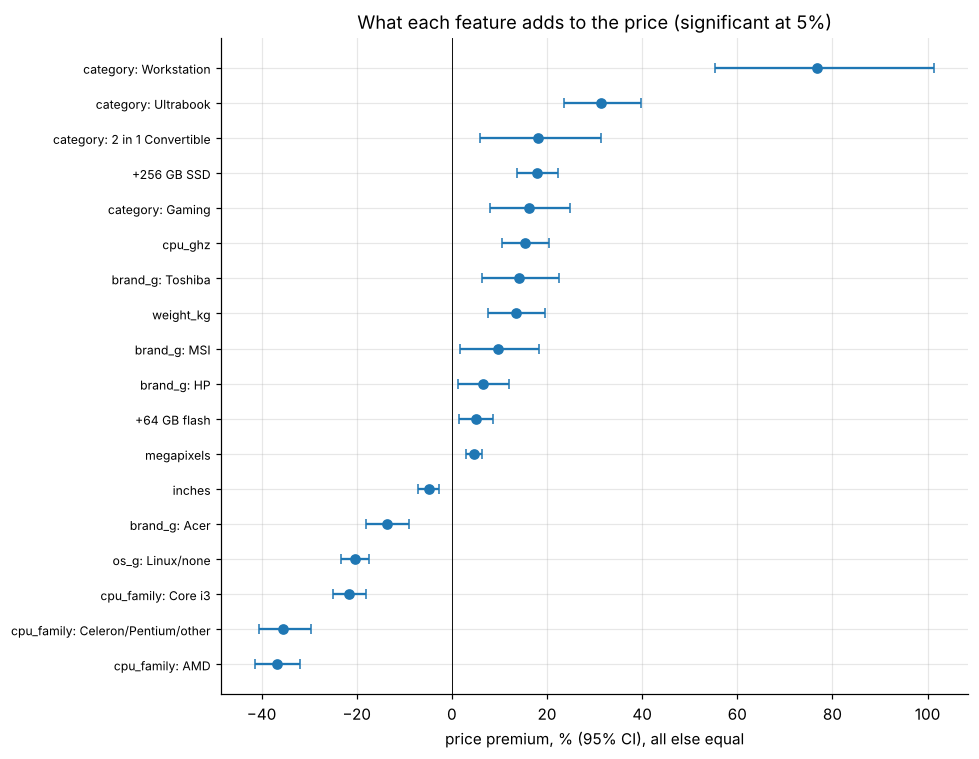

In [5]:
show = prem.sort_values("premium_%")
show = show[show.p < 0.05]
fig, ax = plt.subplots(figsize=(9, 7))
ax.errorbar(show["premium_%"], range(len(show)), xerr=[show["premium_%"] - show["low"], show["high"] - show["premium_%"]], fmt="o", capsize=3)
ax.set_yticks(range(len(show))); ax.set_yticklabels(show.index, fontsize=8); ax.axvline(0, c="k", lw=.6)
ax.set_xlabel("price premium, % (95% CI), all else equal"); ax.set_title("What each feature adds to the price (significant at 5%)")
plt.tight_layout(); plt.savefig(IMG / "premia.png", bbox_inches="tight"); plt.show()

## Prediction: how close can a spec-based model get?

In [6]:
X = pd.get_dummies(d.drop(columns=["price_eur", "brand_g", "os_g"]), columns=["brand", "category", "cpu_family", "gpu", "os"], dtype=float)
y = np.log(d.price_eur)
cv = KFold(5, shuffle=True, random_state=0)
p_gb = cross_val_predict(HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=0), X, y, cv=cv)
p_ols = np.zeros(len(d))
for tr, te in cv.split(d):
    p_ols[te] = smf.ols(f, data=d.iloc[tr]).fit().predict(d.iloc[te])
err = lambda p: np.abs(np.exp(p) - d.price_eur) / d.price_eur
res = pd.DataFrame({m: {"median abs % error": 100 * err(p).median(), "share within 10%": 100 * (err(p) < .1).mean(), "share within 20%": 100 * (err(p) < .2).mean()}
                    for m, p in {"hedonic OLS": p_ols, "gradient boosting": p_gb}.items()}).T
d["fair_price"] = np.exp(p_gb); d["gap_%"] = 100 * (d.price_eur / d.fair_price - 1)
display(res.round(1))
print("Most over-priced vs the model (candidates for a discount or a missing feature in the data):")
pd.concat([raw.loc[d.index, ["Manufacturer", "Model Name"]], d[["price_eur", "fair_price", "gap_%"]]], axis=1).nlargest(5, "gap_%").round(0)

,median abs % error,share within 10%,share within 20%
hedonic OLS,16.6,30.9,57.8
gradient boosting,10.8,46.9,75.4


Most over-priced vs the model (candidates for a discount or a missing feature in the data):


,Manufacturer,Model Name,price_eur,fair_price,gap_%
457,Microsoft,Surface Laptop,989.0,422.0,134.0
1066,Asus,ROG G701VO,3975.0,1811.0,119.0
1088,HP,Chromebook 13,615.0,286.0,115.0
1139,HP,EliteBook 850,2172.0,1025.0,112.0
563,Lenovo,Thinkpad P71,2999.0,1436.0,109.0


## Findings
* **Parsing is most of the job.** Every spec field arrived as text: prices with decimal commas, "128GB SSD +  1TB HDD", resolution inside the screen description, weights in "kg" and "kgs". After parsing, all 1,303 listings were usable with no missing values.
* **The hedonic model explains 84% of log-price variation.** Holding everything else equal, the largest premia come from category (workstation +77%, ultrabook +31%, 2-in-1 +18%, gaming +16%) and from an extra 256 GB of SSD (+18%). Doubling RAM adds about 27%, each extra GHz of CPU clock about 15%, and each extra megapixel of screen about 5%.
* **Cheap components cost a lot of value:** an AMD, Celeron or Pentium processor is priced 35-37% below an otherwise identical Core i5, and shipping without Windows saves about 20%.
* **The "Apple premium" is not significant** once specs are controlled (+7.5%, 95% CI −4% to +20%). Neither is the Core i7 premium over a Core i5 (+1%), because clock speed, GPU and category already capture what i7 machines offer. Hard drives add essentially nothing.
* **Prediction:** gradient boosting prices a laptop within a median 10.8% of its list price (75% of laptops within 20%) under 5-fold cross-validation, against 16.6% for the hedonic regression. The biggest "over-priced" outliers (e.g. a Microsoft Surface Laptop at €989 vs a model value of about €420) are premium designs whose value (build quality, display panel, brand) isn't in the spec sheet. That is the limit of any spec-based price model.